# 06 — Đánh giá Chất lượng Dự đoán và Thiên lệch Độ phổ biến ở Đầu ra (SV1)

Notebook này tổng hợp toàn bộ kết quả đầu ra (`top20.parquet` và `test_metrics.json`) của cả **3 mô hình (`GRU4Rec`, `NARM`, `SASRec`) $\times$ 2 seed (`2024`, `2025`)** để trả lời **Câu hỏi nghiên cứu 1** của đề tài:

> **Câu hỏi 1:** *Mô hình nào có thiên lệch độ phổ biến lớn nhất theo Gini và Coverage@20? Mối quan hệ đánh đổi (trade-off) giữa độ chính xác dự đoán (Recall@20, MRR@20, NDCG@20) và thiên lệch độ phổ biến diễn ra như thế nào?*

### Các bảng và biểu đồ xuất ra từ notebook này:
- `results/tables/model_accuracy.csv`: Bảng tổng hợp `Recall@20`, `MRR@20`, `NDCG@20` (cả Warm All-prefix, Warm Last-item, tách theo nhóm `popular`/`medium`/`rare` và đối chứng Cold-start 20%).
- `results/tables/popularity_bias.csv`: Bảng chỉ số `Coverage@20`, `Gini@20`, `ARP@20` qua từng seed và trung bình `mean ± std`.
- `results/tables/exposure_by_group.csv`: Tỷ trọng lượt hiển thị trong Top-20 phân bổ cho nhóm `popular`, `medium`, `rare`, `cold`.
- `results/figures/catalog_coverage.png`, `results/figures/gini_comparison.png`, `results/figures/average_popularity.png`, `results/figures/exposure_distribution.png`.

## 1. Thiết lập đường dẫn và nạp dữ liệu từ `runs/`

In [1]:
from pathlib import Path
import json
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "BTL-K03-tong-quan-de-tai.md").exists():
            return candidate
    raise FileNotFoundError("Không tìm thấy thư mục gốc dự án BTL-K03.")


PROJECT_ROOT = find_project_root()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from btl_k03.paths import FIGURES_DIR, ITEM_LEVEL_DIR, PROCESSED_DIGI_DIR, RUNS_DIR, TABLES_DIR, ensure_output_dirs
from btl_k03.popularity_metrics import compute_lorenz_curve, evaluate_top20_popularity_bias
from btl_k03.utils import load_experiment_config, load_item_mapping, load_json

ensure_output_dirs()

COMMON_CFG = load_experiment_config("gru4rec")
MODELS = ["gru4rec", "narm", "sasrec"]
SEEDS = COMMON_CFG["seeds"]
item_mapping = load_item_mapping(PROCESSED_DIGI_DIR)

print(f"Models cần tổng hợp : {MODELS}")
print(f"Seeds cần tổng hợp  : {SEEDS}")
print(f"Tổng catalog items  : {len(item_mapping):,} (Warm = {int(item_mapping['is_trainable_warm'].sum()):,}, Cold = {int(item_mapping['is_controlled_cold'].sum()):,})")

Models cần tổng hợp : ['gru4rec', 'narm', 'sasrec']
Seeds cần tổng hợp  : [2024, 2025]
Tổng catalog items  : 37,583 (Warm = 29,936, Cold = 7,647)


## 2. Đọc `test_metrics.json` và `top20.parquet` của 3 mô hình $\times$ 2 seed

In [2]:
accuracy_rows = []
stratified_acc_rows = []
bias_rows = []
exposure_rows = []
cold_diag_rows = []
rec_catalogs = {}

for model_name in MODELS:
    for seed in SEEDS:
        run_dir = RUNS_DIR / model_name / f"seed_{seed}"
        metrics_path = run_dir / "test_metrics.json"
        top20_path = run_dir / "top20.parquet"
        if not metrics_path.is_file() or not top20_path.is_file():
            raise FileNotFoundError(
                f"Chưa có kết quả cho {model_name} (seed={seed}) tại {run_dir}. "
                f"Hãy chạy các notebook 03, 04, 05 trước!"
            )

        payload = load_json(metrics_path)
        top20_df = pd.read_parquet(top20_path)
        pb_summary, catalog_df, grp_exp_df = evaluate_top20_popularity_bias(top20_df, item_mapping, k=20)
        rec_catalogs[(model_name, seed)] = catalog_df

        w_all = payload["test_warm_all_prefix"]
        w_last = payload["test_warm_last_item"]
        cd = payload["cold_start_diagnostic"]

        accuracy_rows.append({
            "model": model_name.upper(),
            "seed": seed,
            "best_epoch": payload["best_epoch"],
            "val_best_mrr@20": payload["best_validation_score"],
            "recall@20": w_all["recall@20"],
            "mrr@20": w_all["mrr@20"],
            "ndcg@20": w_all["ndcg@20"],
            "last_item_recall@20": w_last["recall@20"],
            "last_item_mrr@20": w_last["mrr@20"],
            "last_item_ndcg@20": w_last["ndcg@20"],
            "full_test_effective_recall@20": cd["effective_full_test_recall@20_with_cold_zero"],
        })

        for s_row in payload["test_warm_by_popularity_group"]:
            stratified_acc_rows.append({"model": model_name.upper(), "seed": seed, **s_row})

        bias_rows.append({
            "model": model_name.upper(),
            "seed": seed,
            **pb_summary,
        })

        for _, e_row in grp_exp_df.iterrows():
            exposure_rows.append({"model": model_name.upper(), "seed": seed, **e_row.to_dict()})

        cold_diag_rows.append({"model": model_name.upper(), "seed": seed, **cd})

accuracy_df = pd.DataFrame(accuracy_rows)
stratified_acc_df = pd.DataFrame(stratified_acc_rows)
bias_df = pd.DataFrame(bias_rows)
exposure_df = pd.DataFrame(exposure_rows)
cold_diag_df = pd.DataFrame(cold_diag_rows)

# Xuất ra results/tables/
accuracy_df.to_csv(TABLES_DIR / "model_accuracy.csv", index=False)
bias_df.to_csv(TABLES_DIR / "popularity_bias.csv", index=False)
exposure_df.to_csv(TABLES_DIR / "exposure_by_group.csv", index=False)

print("=== BẢNG 1: CHẤT LƯỢNG DỰ ĐOÁN (SANITY CHECK ACCURACY) CỦA 3 MÔ HÌNH QUA 2 SEED ===")
display(accuracy_df)

print("\n=== BẢNG 2: TRUNG BÌNH ± ĐỘ LỆCH CHUẨN (MEAN ± STD) VỀ CHẤT LƯỢNG VÀ POPULARITY BIAS ===")
merged_summary = pd.merge(
    accuracy_df[["model", "seed", "recall@20", "mrr@20", "ndcg@20"]],
    bias_df[["model", "seed", "coverage_warm@20", "coverage_full@20", "gini_warm@20", "arp@20", "popular_group_exposure_share_pct", "rare_group_exposure_share_pct"]],
    on=["model", "seed"],
)
agg_summary = merged_summary.groupby("model", sort=False).agg(["mean", "std"])
display(agg_summary)

=== BẢNG 1: CHẤT LƯỢNG DỰ ĐOÁN (SANITY CHECK ACCURACY) CỦA 3 MÔ HÌNH QUA 2 SEED ===


,model,seed,best_epoch,val_best_mrr@20,recall@20,mrr@20,ndcg@20,last_item_recall@20,last_item_mrr@20,last_item_ndcg@20,full_test_effective_recall@20
0,GRU4REC,2024,16,0.2025,0.5555,0.1979,0.2770,0.5591,0.2134,0.2902,0.3117
1,GRU4REC,2025,15,0.2020,0.5585,0.1999,0.2792,0.5588,0.2170,0.2928,0.3134
2,NARM,2024,15,0.2036,0.5632,0.1980,0.2789,0.5686,0.2149,0.2936,0.3160
3,NARM,2025,20,0.2045,0.5618,0.1976,0.2782,0.5640,0.2139,0.2917,0.3152
4,SASREC,2024,12,0.2115,0.5705,0.2075,0.2877,0.5783,0.2260,0.3041,0.3201
5,SASREC,2025,8,0.2125,0.5753,0.2082,0.2894,0.5800,0.2287,0.3066,0.3228



=== BẢNG 2: TRUNG BÌNH ± ĐỘ LỆCH CHUẨN (MEAN ± STD) VỀ CHẤT LƯỢNG VÀ POPULARITY BIAS ===


seed        recall@20        mrr@20        ndcg@20         \
              mean    std      mean    std   mean    std    mean    std   
model                                                                     
GRU4REC 2,024.5000 0.7071    0.5570 0.0021 0.1989 0.0014  0.2781 0.0016   
NARM    2,024.5000 0.7071    0.5625 0.0009 0.1978 0.0003  0.2786 0.0005   
SASREC  2,024.5000 0.7071    0.5729 0.0034 0.2079 0.0005  0.2885 0.0012   

        coverage_warm@20        coverage_full@20        gini_warm@20         \
                    mean    std             mean    std         mean    std   
model                                                                         
GRU4REC           0.8851 0.0050           0.7050 0.0040       0.7036 0.0036   
NARM              0.8858 0.0145           0.7056 0.0116       0.7061 0.0059   
SASREC            0.9176 0.0053           0.7309 0.0042       0.6885 0.0033   

         arp@20        popular_group_exposure_share_pct         \
           mean    std                             mean    std   
model                                                            
GRU4REC 77.5180 0.9175                          63.9590 0.2150   
NARM    76.5658 0.7664                          64.1456 0.1205   
SASREC  73.8963 0.0840                          62.4878 0.0385   

        rare_group_exposure_share_pct         
                                 mean    std  
model                                         
GRU4REC                        4.2710 0.0212  
NARM                           4.1631 0.0682  
SASREC                         4.7266 0.0786

## 3. Phân tích chi tiết theo nhóm độ phổ biến (`Popular` / `Medium` / `Rare` / `Cold`)

In [3]:
print("=== BẢNG 3: ĐỘ CHÍNH XÁC DỰ ĐOÁN (RECALL@20, MRR@20) THEO NHÓM TARGET TRONG TEST ===")
display(
    stratified_acc_df.groupby(["model", "target_group"], sort=False)[["num_examples", "recall@20", "mrr@20", "ndcg@20"]].mean()
)

print("\n=== BẢNG 4: PHÂN BỔ LƯỢT HIỂN THỊ TOP-20 (EXPOSURE SHARE) THEO NHÓM POPULARITY ===")
display(
    exposure_df.groupby(["model", "popularity_group"], sort=False)[
        ["catalog_items", "warm_catalog_share_pct", "train_interaction_share_pct", "exposure_share_pct", "exposure_to_train_ratio", "within_group_coverage_pct"]
    ].mean()
)

=== BẢNG 3: ĐỘ CHÍNH XÁC DỰ ĐOÁN (RECALL@20, MRR@20) THEO NHÓM TARGET TRONG TEST ===


num_examples  recall@20  mrr@20  ndcg@20
model   target_group                                          
GRU4REC all_warm       40,001.0000     0.5570  0.1989   0.2781
        popular        23,091.0000     0.6470  0.2426   0.3328
        medium         14,300.0000     0.4536  0.1434   0.2109
        rare            2,610.0000     0.3276  0.1160   0.1621
NARM    all_warm       40,001.0000     0.5625  0.1978   0.2786
        popular        23,091.0000     0.6534  0.2424   0.3342
        medium         14,300.0000     0.4586  0.1425   0.2114
        rare            2,610.0000     0.3274  0.1060   0.1543
SASREC  all_warm       40,001.0000     0.5729  0.2079   0.2885
        popular        23,091.0000     0.6536  0.2420   0.3338
        medium         14,300.0000     0.4810  0.1658   0.2343
        rare            2,610.0000     0.3628  0.1362   0.1858


=== BẢNG 4: PHÂN BỔ LƯỢT HIỂN THỊ TOP-20 (EXPOSURE SHARE) THEO NHÓM POPULARITY ===


catalog_items  warm_catalog_share_pct  \
model   popularity_group                                          
GRU4REC popular              6,112.0000                 20.4169   
        medium              16,940.0000                 56.5874   
        rare                 6,884.0000                 22.9957   
        cold                 7,647.0000                  0.0000   
NARM    popular              6,112.0000                 20.4169   
        medium              16,940.0000                 56.5874   
        rare                 6,884.0000                 22.9957   
        cold                 7,647.0000                  0.0000   
SASREC  popular              6,112.0000                 20.4169   
        medium              16,940.0000                 56.5874   
        rare                 6,884.0000                 22.9957   
        cold                 7,647.0000                  0.0000   

                          train_interaction_share_pct  exposure_share_pct  \
model   popularity_group                                                    
GRU4REC popular                               60.6522             63.9590   
        medium                                33.5715             31.7700   
        rare                                   5.7763              4.2710   
        cold                                   0.0000              0.0000   
NARM    popular                               60.6522             64.1456   
        medium                                33.5715             31.6913   
        rare                                   5.7763              4.1631   
        cold                                   0.0000              0.0000   
SASREC  popular                               60.6522             62.4878   
        medium                                33.5715             32.7856   
        rare                                   5.7763              4.7266   
        cold                                   0.0000              0.0000   

                          exposure_to_train_ratio  within_group_coverage_pct  
model   popularity_group                                                      
GRU4REC popular                            1.0545                    99.5991  
        medium                             0.9463                    90.5903  
        rare                               0.7394                    73.5474  
        cold                               0.0000                     0.0000  
NARM    popular                            1.0576                    99.5255  
        medium                             0.9440                    90.5962  
        rare                               0.7207                    73.8960  
        cold                               0.0000                     0.0000  
SASREC  popular                            1.0303                    99.7873  
        medium                             0.9766                    93.3914  
        rare                               0.8183                    80.5999  
        cold                               0.0000                     0.0000

## 4. Trực quan hóa và Xuất 4 biểu đồ chuẩn cho Báo cáo & Slide

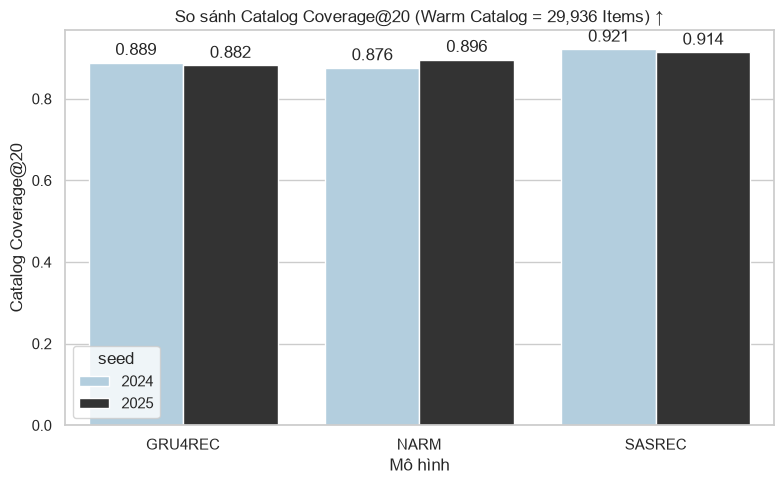

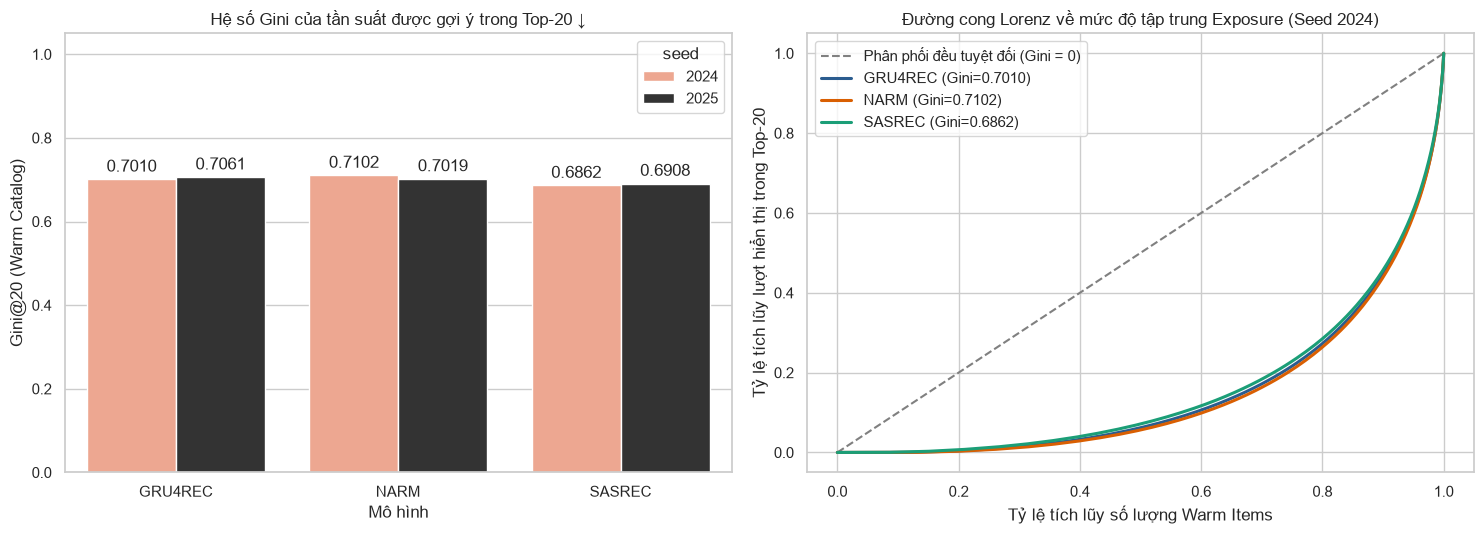

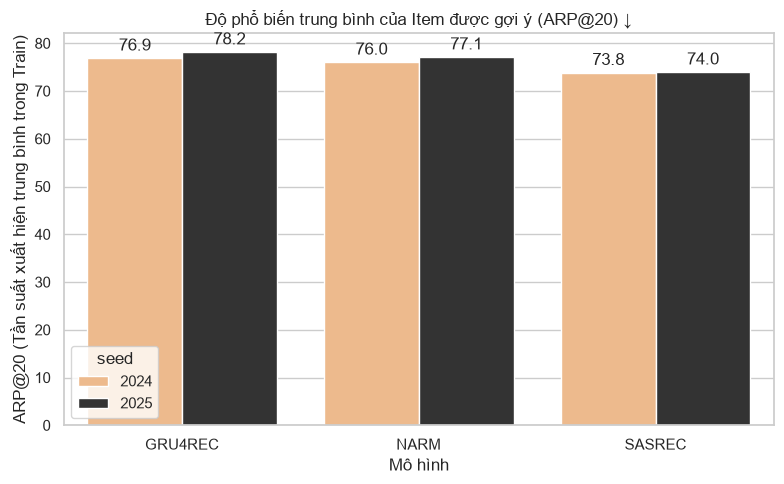

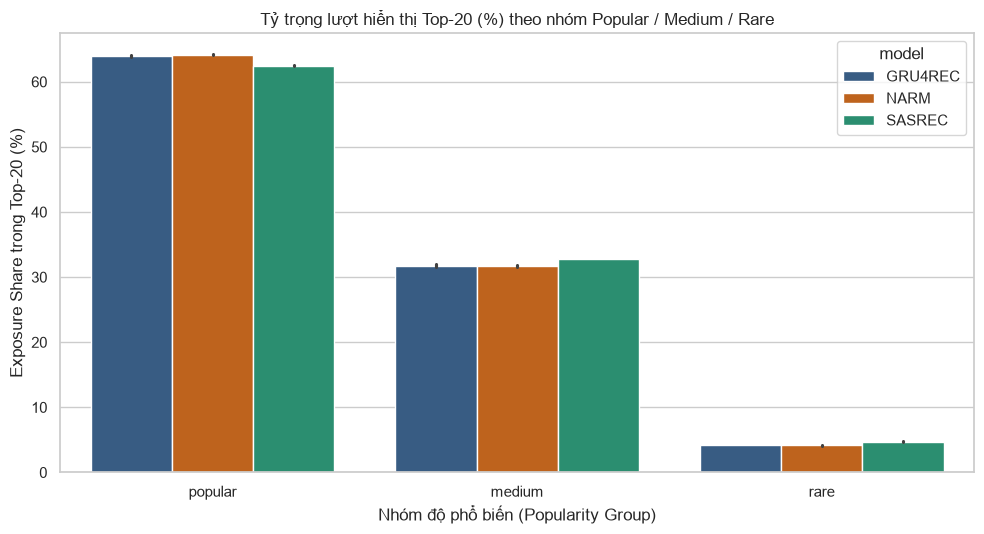

Đã lưu toàn bộ bảng vào results/tables/ và biểu đồ vào results/figures/.


In [4]:
palette_models = {"GRU4REC": "#2b5c8f", "NARM": "#d95f02", "SASREC": "#1b9e77"}

# Hình 1: Catalog Coverage@20
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=bias_df, x="model", y="coverage_warm@20", hue="seed", palette="Blues_d", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)
ax.set_title("So sánh Catalog Coverage@20 (Warm Catalog = 29,936 Items) ↑")
ax.set_xlabel("Mô hình")
ax.set_ylabel("Catalog Coverage@20")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "catalog_coverage.png", dpi=300)
plt.show()

# Hình 2: Gini Coefficient & Lorenz Curve
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.barplot(data=bias_df, x="model", y="gini_warm@20", hue="seed", palette="Reds_d", ax=axes[0])
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.4f", padding=3)
axes[0].set_title("Hệ số Gini của tần suất được gợi ý trong Top-20 ↓")
axes[0].set_xlabel("Mô hình")
axes[0].set_ylabel("Gini@20 (Warm Catalog)")
axes[0].set_ylim(0, 1.05)

axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Phân phối đều tuyệt đối (Gini = 0)")
first_seed = SEEDS[0]
for m in MODELS:
    cat_df = rec_catalogs[(m, first_seed)]
    warm_counts = cat_df.loc[cat_df["candidate_for_main_evaluation"], "rec_count"].to_numpy()
    lx, ly = compute_lorenz_curve(warm_counts)
    g_val = bias_df.loc[(bias_df["model"] == m.upper()) & (bias_df["seed"] == first_seed), "gini_warm@20"].iloc[0]
    axes[1].plot(lx, ly, linewidth=2.2, color=palette_models[m.upper()], label=f"{m.upper()} (Gini={g_val:.4f})")
axes[1].set_title(f"Đường cong Lorenz về mức độ tập trung Exposure (Seed {first_seed})")
axes[1].set_xlabel("Tỷ lệ tích lũy số lượng Warm Items")
axes[1].set_ylabel("Tỷ lệ tích lũy lượt hiển thị trong Top-20")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "gini_comparison.png", dpi=300)
plt.show()

# Hình 3: Average Recommendation Popularity (ARP@20)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=bias_df, x="model", y="arp@20", hue="seed", palette="Oranges_d", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)
ax.set_title("Độ phổ biến trung bình của Item được gợi ý (ARP@20) ↓")
ax.set_xlabel("Mô hình")
ax.set_ylabel("ARP@20 (Tần suất xuất hiện trung bình trong Train)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "average_popularity.png", dpi=300)
plt.show()

# Hình 4: Phân bổ Exposure theo nhóm Popular / Medium / Rare so với tỷ trọng trong Train
fig, ax = plt.subplots(figsize=(10, 5.5))
warm_exp = exposure_df.loc[exposure_df["popularity_group"].isin(["popular", "medium", "rare"])].copy()
sns.barplot(
    data=warm_exp,
    x="popularity_group",
    y="exposure_share_pct",
    hue="model",
    order=["popular", "medium", "rare"],
    palette=palette_models,
    ax=ax,
)
ax.set_title("Tỷ trọng lượt hiển thị Top-20 (%) theo nhóm Popular / Medium / Rare")
ax.set_xlabel("Nhóm độ phổ biến (Popularity Group)")
ax.set_ylabel("Exposure Share trong Top-20 (%)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "exposure_distribution.png", dpi=300)
plt.show()

print("Đã lưu toàn bộ bảng vào results/tables/ và biểu đồ vào results/figures/.")